In [ ]:
from google.colab import files
files.upload()

Saving archive.zip to archive.zip


{'archive.zip': b'PK\x03\x04-\x00\x00\x08\x08\x00L8\x82[\t\xfeU\x19\xff\xff\xff\xff\xff\xff\xff\xff\r\x00\x14\x00Fake_Real.csv\x01\x00\x10\x00SPN\x03\x00\x00\x00\x00\xda\xa7\xd9\x00\x00\x00\x00\x00\xbc\xbdK\x8e$I\xb2-6\xbf\xc0\xdd\x83/\xa0\x1f\x90\x91YU]\xb9\x02\xce8!8&\xd4\xcd\xd4\xdd-\xc2\xdc\xcc\xcb>\xe1\xe99\xea=p\xc2\x07\\N\xb9\t\x0e\xb8\x97\xde\x00\xb7@9\xe7\x88\xa8\xa9yD\xf5\x07x\xe0\x05nvE\x84\xbb\x99\xaa\xa8\xa8\xfc\xe5\xc8\xff\xfb\x7f\xff?K\xfe\xb1\xfce^\x8f\xaf\xb9Y\xfe\xd2\xe7\xf7\xdc\xff\xe7\x7f\x0c\xf9~x\x8c\xd3\xdba\xca\xeb\x92\xa7\xf9\xb0\xce\x87<\xbcw\xd38\\\xf3\xb0\xa4\xfep\x9e\xc6\xf5v\x98\xbb<M\xe9\xd0\xf4\xeb\xf1\x90\xe6\xb7\xdc>}\xea6\x8d\x8b=\xb6\x1b\x87C:\xe7\xa1y\xfc\xfdo\xff}>t\xc3|\xb3\xdf\x8e\xd3\xc1~\x97\'\xfb\\7\xbc\xe7y\xe9\xcei\xc9\x87\xfb%/\x97<\xd5_\xb8\xe4\xd4\x1e\xe6f\\\x16{\xe2\xda\xd9\xff\xbcwco\x1fn\xed\x9b\xb6\xbe\x01\xaf\x1a\xfb\xae\xe9\xf2|\x98S\xd7\x1e\x8e\xb9\xefl+\x87&MG{y\xdb\x8d?\xba6\x1f\xae\xe9\xd5\xde\xda\x8c\xc32u\xc7\x15+h\xfa\xee\x8a

In [ ]:
!unzip archive.zip


Archive:  archive.zip
  inflating: Fake_Real.csv           


In [ ]:
import pandas as pd
df = pd.read_csv('Fake_Real.csv')
print(df.shape)
print(df.head())

(15998, 3)
                                                text       subject  level
0  new york reuters us environmental group sierra...  politicsNews    0.0
1  washington reuters us air force asked industry...  politicsNews    0.0
2  saturday paul ryan posted photo instagram phot...          News    1.0
3  america keeps waiting word hillary indicted ob...      politics    1.0
4                   religion peace ht weasel zippers     left-news    1.0


In [ ]:
print(df['level'].value_counts())
print("\n")
print(df['subject'].value_counts())
print("\n")
print(df.isnull().sum())

level
0.0    9681
1.0    6316
Name: count, dtype: int64


subject
National           3319
politicsNews       1721
worldnews          1542
News               1362
International      1181
Sports             1171
politics           1064
Miscellaneous       770
left-news           738
Editorial           646
Politics            560
Entertainment       499
Government News     237
Lifestyle           213
Crime               209
Education           195
Finance             190
Technology          157
US_News             118
Middle-east         105
Name: count, dtype: int64


text       123
subject      1
level        1
dtype: int64


In [ ]:
!pip install langdetect

df = df.dropna(subset=['text', 'level'])
print("After dropping nulls:", df.shape)


df['label'] = df['level'].astype(int)


from langdetect import detect

def detect_lang(text):
    try:
        return detect(str(text))
    except:
        return 'unknown'

print("Language detection")
df['language'] = df['text'].apply(detect_lang)
print(df['language'].value_counts())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 14.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=eac89a3e09a006b53ab2b5d46d94095cad920d2b9b2444ddf8932d2075e88215
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect
After dropping nulls: (15874, 4)
Language detection
language
bn    9091
en    6759
fr       5
pl       2
sw       2
cy       2
nl       1
ca       1
sk       1
id       1
pt       1
sl       1
sq       1
it       1
af       1
tl       1
lt       1
tr       1
de       1
Name: count, dtype: int64


In [ ]:
df = df[df['language'].isin(['bn', 'en'])]
print("Final dataset shape:", df.shape)
print("\nLanguage distribution:")
print(df['language'].value_counts())
print("\nFake/Real distribution:")
print(df['label'].value_counts())

Final dataset shape: (15850, 5)

Language distribution:
language
bn    9091
en    6759
Name: count, dtype: int64

Fake/Real distribution:
label
0    9545
1    6305
Name: count, dtype: int64


In [ ]:
import re

def clean_text(text):
    text = str(text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    return text

df['clean_text'] = df['text'].apply(clean_text)
print("Preprocessing done!")
print(df[['text', 'clean_text']].head(3))

Preprocessing done!
                                                text  \
0  new york reuters us environmental group sierra...   
1  washington reuters us air force asked industry...   
2  saturday paul ryan posted photo instagram phot...   

                                          clean_text  
0  new york reuters us environmental group sierra...  
1  washington reuters us air force asked industry...  
2  saturday paul ryan posted photo instagram phot...  


In [ ]:
print(df[df['language'] == 'bn'][['text', 'clean_text']].head(3))

                                                   text  \
6888  দশম জাতীয় সংসদের মেয়াদ শেষ হয়ে যাচ্ছে। কার্যত ...   
6889  একাদশ জাতীয় সংসদ নির্বাচনকে সামনে রেখে সাংগঠনি...   
6890  গাজীপুরে জোড়া খুন মামলার প্রধান আসামি মাদ্রাসা...   

                                             clean_text  
6888  দশম জাতীয় সংসদের মেয়াদ শেষ হয়ে যাচ্ছে। কার্যত ...  
6889  একাদশ জাতীয় সংসদ নির্বাচনকে সামনে রেখে সাংগঠনি...  
6890  গাজীপুরে জোড়া খুন মামলার প্রধান আসামি মাদ্রাসা...  


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Bangla আর English আলাদা করো
df_bn = df[df['language'] == 'bn']
df_en = df[df['language'] == 'en']

# Train-Test split
X_bn_train, X_bn_test, y_bn_train, y_bn_test = train_test_split(
    df_bn['clean_text'], df_bn['label'], test_size=0.2, random_state=42)

X_en_train, X_en_test, y_en_train, y_en_test = train_test_split(
    df_en['clean_text'], df_en['label'], test_size=0.2, random_state=42)

print("Bangla train:", len(X_bn_train), "| test:", len(X_bn_test))
print("English train:", len(X_en_train), "| test:", len(X_en_test))

Bangla train: 7272 | test: 1819
English train: 5407 | test: 1352


In [ ]:
# Bangla SVM
tfidf_bn = TfidfVectorizer(max_features=50000)
X_bn_train_tfidf = tfidf_bn.fit_transform(X_bn_train)
X_bn_test_tfidf = tfidf_bn.transform(X_bn_test)

svm_bn = LinearSVC()
svm_bn.fit(X_bn_train_tfidf, y_bn_train)
y_bn_pred = svm_bn.predict(X_bn_test_tfidf)

print("=== Bangla SVM Results ===")
print("Accuracy:", accuracy_score(y_bn_test, y_bn_pred))
print(classification_report(y_bn_test, y_bn_pred))

# English SVM
tfidf_en = TfidfVectorizer(max_features=50000)
X_en_train_tfidf = tfidf_en.fit_transform(X_en_train)
X_en_test_tfidf = tfidf_en.transform(X_en_test)

svm_en = LinearSVC()
svm_en.fit(X_en_train_tfidf, y_en_train)
y_en_pred = svm_en.predict(X_en_test_tfidf)

print("\n=== English SVM Results ===")
print("Accuracy:", accuracy_score(y_en_test, y_en_pred))
print(classification_report(y_en_test, y_en_pred))

=== Bangla SVM Results ===
Accuracy: 0.7300714678394722
              precision    recall  f1-score   support

           0       0.60      0.44      0.51       576
           1       0.77      0.87      0.81      1243

    accuracy                           0.73      1819
   macro avg       0.69      0.65      0.66      1819
weighted avg       0.72      0.73      0.72      1819


=== English SVM Results ===
Accuracy: 0.9992603550295858
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1351
           1       0.00      0.00      0.00         1

    accuracy                           1.00      1352
   macro avg       0.50      0.50      0.50      1352
weighted avg       1.00      1.00      1.00      1352



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
!pip install transformers torch datasets

In [ ]:
from transformers import AutoTokenizer
import torch


tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['label'], test_size=0.2, random_state=42)

print("Train size:", len(X_train))
print("Test size:", len(X_test))
print("Tokenizer loaded!")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

NameError: name 'df' is not defined

In [ ]:
!pip install langdetect -q

from google.colab import files
files.upload()
!unzip archive.zip

!pip install langdetect -q
# Step 1: Libraries
import pandas as pd
import re
from langdetect import detect
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
from transformers import AutoTokenizer
import torch

# Step 2: Data load
df = pd.read_csv('Fake_Real.csv')
df = df.dropna(subset=['text', 'level'])
df['label'] = df['level'].astype(int)

# Step 3: Clean text
def clean_text(text):
    text = str(text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['clean_text'] = df['text'].apply(clean_text)

# Step 4: Language detection
def detect_lang(text):
    try:
        return detect(str(text))
    except:
        return 'unknown'

print("Language detection চলছে... ৩-৫ মিনিট লাগবে")
df['language'] = df['text'].apply(detect_lang)
df = df[df['language'].isin(['bn', 'en'])]
print("Done! Shape:", df.shape)

Saving archive.zip to archive (1).zip
Archive:  archive.zip
  inflating: Fake_Real.csv           
Language detection চলছে... ৩-৫ মিনিট লাগবে
Done! Shape: (15855, 6)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
!pip install langdetect -q
!unzip -o archive.zip

import pandas as pd
import re
from langdetect import detect

df = pd.read_csv('Fake_Real.csv')
df = df.dropna(subset=['text', 'level'])
df['label'] = df['level'].astype(int)

def clean_text(text):
    text = str(text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['clean_text'] = df['text'].apply(clean_text)

def detect_lang(text):
    try:
        return detect(str(text))
    except:
        return 'unknown'

df['language'] = df['text'].apply(detect_lang)
df = df[df['language'].isin(['bn', 'en'])]
print("Ready! Shape:", df.shape)

Archive:  archive.zip
  inflating: Fake_Real.csv           
Ready! Shape: (15852, 6)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp Fake_Real.csv "/content/drive/MyDrive/Fake_Real.csv"
print("Saved in Drive")

Saved in Drive


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW
from sklearn.model_selection import train_test_split

# Tokenizer load
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

# Train-Test split
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'].tolist(),
    df['label'].tolist(),
    test_size=0.2,
    random_state=42
)

# Dataset class
class NewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = NewsDataset(X_train, y_train, tokenizer)
test_dataset = NewsDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

print("Dataset ready!")
print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Dataset ready!
Train batches: 793
Test batches: 199


In [ ]:
from torch.optim import AdamW

# Model load
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

model = AutoModelForSequenceClassification.from_pretrained(
    "xlm-roberta-base",
    num_labels=2
)
model = model.to(device)

# Optimizer
optimizer = AdamW(model.parameters(), lr=2e-5)

# Training loop
EPOCHS = 3

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for batch_idx, batch in enumerate(train_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        if batch_idx % 100 == 0:
            print(f"Epoch {epoch+1} | Batch {batch_idx}/{len(train_loader)} | Loss: {loss.item():.4f}")

    print(f"\n✅ Epoch {epoch+1} End! Average Loss: {total_loss/len(train_loader):.4f}\n")

print("Training complete!")

# Drive save
model.save_pretrained("/content/drive/MyDrive/xlm_roberta_fakenews_v2")
tokenizer.save_pretrained("/content/drive/MyDrive/xlm_roberta_fakenews_v2")
print("Model saved to Drive!")

Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 | Batch 0/794 | Loss: 0.6503
Epoch 1 | Batch 100/794 | Loss: 0.2571
Epoch 1 | Batch 200/794 | Loss: 0.2911
Epoch 1 | Batch 300/794 | Loss: 0.2378
Epoch 1 | Batch 400/794 | Loss: 0.4209
Epoch 1 | Batch 500/794 | Loss: 0.3245
Epoch 1 | Batch 600/794 | Loss: 0.4046
Epoch 1 | Batch 700/794 | Loss: 0.3279

✅ Epoch 1 End! Average Loss: 0.3598

Epoch 2 | Batch 0/794 | Loss: 0.2159
Epoch 2 | Batch 100/794 | Loss: 0.3502
Epoch 2 | Batch 200/794 | Loss: 0.3230
Epoch 2 | Batch 300/794 | Loss: 0.2630
Epoch 2 | Batch 400/794 | Loss: 0.2085
Epoch 2 | Batch 500/794 | Loss: 0.2800
Epoch 2 | Batch 600/794 | Loss: 0.2665
Epoch 2 | Batch 700/794 | Loss: 0.2946

✅ Epoch 2 End! Average Loss: 0.3313

Epoch 3 | Batch 0/794 | Loss: 0.1711
Epoch 3 | Batch 100/794 | Loss: 0.1997
Epoch 3 | Batch 200/794 | Loss: 0.2021
Epoch 3 | Batch 300/794 | Loss: 0.3174
Epoch 3 | Batch 400/794 | Loss: 0.1645
Epoch 3 | Batch 500/794 | Loss: 0.4089
Epoch 3 | Batch 600/794 | Loss: 0.1402
Epoch 3 | Batch 700/794 | Loss: 0

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to Drive!


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'].tolist(),
    df['label'].tolist(),
    test_size=0.2,
    random_state=42
)

class NewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = NewsDataset(X_train, y_train, tokenizer)
test_dataset = NewsDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

print("Train loader ready!")

Train loader ready!


In [ ]:
model.save_pretrained("/content/drive/MyDrive/xlm_roberta_fakenews")
tokenizer.save_pretrained("/content/drive/MyDrive/xlm_roberta_fakenews")
print("Model saved to Drive!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to Drive!


In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    "/content/drive/MyDrive/xlm_roberta_fakenews"
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
!pip install langdetect -q

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import re
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# Data load
df = pd.read_csv('/content/drive/MyDrive/Fake_Real.csv')

def clean_text(text):
    text = str(text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['label'] = df['level'].dropna()
df = df.dropna(subset=['level'])
df['label'] = df['level'].astype(int)
print("Data ready! Shape:", df.shape)

# Model load
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = AutoModelForSequenceClassification.from_pretrained("/content/drive/MyDrive/xlm_roberta_fakenews")
tokenizer = AutoTokenizer.from_pretrained("/content/drive/MyDrive/xlm_roberta_fakenews")
model = model.to(device)
print("Model loaded! Device:", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data ready! Shape: (15997, 4)


Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

Model loaded! Device: cuda


In [ ]:
df = df.dropna(subset=['level', 'text'])
df['label'] = df['level'].astype(int)
df['clean_text'] = df['text'].apply(clean_text)
print("Data ready! Shape:", df.shape)
print(df.columns)

/tmp/ipykernel_1718/2852212049.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['label'] = df['level'].astype(int)


Data ready! Shape: (15874, 5)
Index(['text', 'subject', 'level', 'label', 'clean_text'], dtype='object')


/tmp/ipykernel_1718/2852212049.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['clean_text'] = df['text'].apply(clean_text)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'].tolist(),
    df['label'].tolist(),
    test_size=0.2,
    random_state=42
)

class NewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

test_dataset = NewsDataset(X_test, y_test, tokenizer)
test_loader = DataLoader(test_dataset, batch_size=16)
print("Test dataset ready! Samples:", len(X_test))

Test dataset ready! Samples: 3175


In [ ]:
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("=== XLM-RoBERTa Overall Results ===")
print("Accuracy:", accuracy_score(all_labels, all_preds))
print(classification_report(all_labels, all_preds))

=== XLM-RoBERTa Overall Results ===
Accuracy: 0.8248818897637795
              precision    recall  f1-score   support

           0       0.98      0.73      0.83      1922
           1       0.70      0.98      0.81      1253

    accuracy                           0.82      3175
   macro avg       0.84      0.85      0.82      3175
weighted avg       0.87      0.82      0.83      3175



In [ ]:
from langdetect import detect

def detect_lang(text):
    try:
        return detect(str(text))
    except:
        return 'unknown'


test_df = pd.DataFrame({'text': X_test, 'label': y_test, 'pred': all_preds})
test_df['language'] = test_df['text'].apply(detect_lang)

# Bangla results
bn_df = test_df[test_df['language'] == 'bn']
print("=== Bangla Results ===")
print("Accuracy:", accuracy_score(bn_df['label'], bn_df['pred']))
print(classification_report(bn_df['label'], bn_df['pred']))

# English results
en_df = test_df[test_df['language'] == 'en']
print("=== English Results ===")
print("Accuracy:", accuracy_score(en_df['label'], en_df['pred']))
print(classification_report(en_df['label'], en_df['pred']))

=== Bangla Results ===
Accuracy: 0.701081081081081
              precision    recall  f1-score   support

           0       0.73      0.12      0.21       600
           1       0.70      0.98      0.82      1250

    accuracy                           0.70      1850
   macro avg       0.72      0.55      0.51      1850
weighted avg       0.71      0.70      0.62      1850

=== English Results ===
Accuracy: 0.9977272727272727
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1317
           1       0.00      0.00      0.00         3

    accuracy                           1.00      1320
   macro avg       0.50      0.50      0.50      1320
weighted avg       1.00      1.00      1.00      1320



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Bangla আর English আলাদা করো
from langdetect import detect

test_df['language'] = test_df['text'].apply(detect_lang)
df_bn = df[df['text'].apply(detect_lang) == 'bn']
df_en = df[df['text'].apply(detect_lang) == 'en']

# Bangla SVM
X_bn_train, X_bn_test, y_bn_train, y_bn_test = train_test_split(
    df_bn['clean_text'], df_bn['label'], test_size=0.2, random_state=42)

tfidf_bn = TfidfVectorizer(max_features=50000)
X_bn_train_tfidf = tfidf_bn.fit_transform(X_bn_train)
X_bn_test_tfidf = tfidf_bn.transform(X_bn_test)

svm_bn = CalibratedClassifierCV(LinearSVC())
svm_bn.fit(X_bn_train_tfidf, y_bn_train)

# English SVM
X_en_train, X_en_test, y_en_train, y_en_test = train_test_split(
    df_en['clean_text'], df_en['label'], test_size=0.2, random_state=42)

tfidf_en = TfidfVectorizer(max_features=50000)
X_en_train_tfidf = tfidf_en.fit_transform(X_en_train)
X_en_test_tfidf = tfidf_en.transform(X_en_test)

svm_en = CalibratedClassifierCV(LinearSVC())
svm_en.fit(X_en_train_tfidf, y_en_train)

print("SVM trained!")

SVM trained!


In [ ]:
import numpy as np


test_texts = X_test
test_labels = y_test

ensemble_preds = []

model.eval()

for text, true_label in zip(test_texts, test_labels):
    lang = detect_lang(text)

    # XLM-RoBERTa probability
    encoding = tokenizer(
        text,
        max_length=256,
        padding='max_length',
        truncation=True,
        return_tensors='pt'
    ).to(device)

    with torch.no_grad():
        output = model(**encoding)
        xlm_prob = torch.softmax(output.logits, dim=1).cpu().numpy()[0]

    # SVM probability
    if lang == 'bn':
        tfidf_vec = tfidf_bn.transform([text])
        svm_prob = svm_bn.predict_proba(tfidf_vec)[0]
    else:
        tfidf_vec = tfidf_en.transform([text])
        svm_prob = svm_en.predict_proba(tfidf_vec)[0]

    # Average ensemble
    avg_prob = (xlm_prob + svm_prob) / 2
    ensemble_preds.append(np.argmax(avg_prob))

print("=== Ensemble Results ===")
print("Accuracy:", accuracy_score(test_labels, ensemble_preds))
print(classification_report(test_labels, ensemble_preds))

=== Ensemble Results ===
Accuracy: 0.8500787401574803
              precision    recall  f1-score   support

           0       0.99      0.76      0.86      1922
           1       0.73      0.98      0.84      1253

    accuracy                           0.85      3175
   macro avg       0.86      0.87      0.85      3175
weighted avg       0.89      0.85      0.85      3175



In [ ]:
# Ensemble results by language
ensemble_df = pd.DataFrame({
    'text': test_texts,
    'label': test_labels,
    'pred': ensemble_preds
})
ensemble_df['language'] = ensemble_df['text'].apply(detect_lang)

# Bangla
bn_df = ensemble_df[ensemble_df['language'] == 'bn']
print("=== Bangla Ensemble Results ===")
print("Accuracy:", accuracy_score(bn_df['label'], bn_df['pred']))
print(classification_report(bn_df['label'], bn_df['pred']))

# English
en_df = ensemble_df[ensemble_df['language'] == 'en']
print("=== English Ensemble Results ===")
print("Accuracy:", accuracy_score(en_df['label'], en_df['pred']))
print(classification_report(en_df['label'], en_df['pred']))

=== Bangla Ensemble Results ===
Accuracy: 0.7443243243243243
              precision    recall  f1-score   support

           0       0.90      0.24      0.38       600
           1       0.73      0.99      0.84      1250

    accuracy                           0.74      1850
   macro avg       0.81      0.61      0.61      1850
weighted avg       0.78      0.74      0.69      1850

=== English Ensemble Results ===
Accuracy: 0.9977289931869796
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1318
           1       0.00      0.00      0.00         3

    accuracy                           1.00      1321
   macro avg       0.50      0.50      0.50      1321
weighted avg       1.00      1.00      1.00      1321



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import torch
import numpy as np

def get_attention_words(text, model, tokenizer, device):

    inputs = tokenizer(
        text,
        max_length=256,
        truncation=True,
        return_tensors='pt'
    ).to(device)


    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    # Prediction
    probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]
    pred = np.argmax(probs)
    confidence = probs[pred] * 100

    # Last layer attention average
    attention = outputs.attentions[-1]
    attention = attention.mean(dim=1).squeeze()
    attention = attention.mean(dim=0).cpu().numpy()


    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'].squeeze())


    word_attention = []
    for token, attn in zip(tokens, attention):
        if token not in ['<s>', '</s>', '<pad>']:
            word_attention.append((token, attn))

    # Top 5 suspicious words
    word_attention.sort(key=lambda x: x[1], reverse=True)
    top_words = word_attention[:5]

    label = "FAKE" if pred == 0 else "REAL"

    print(f"Result: {label} ({confidence:.1f}% confidence)")
    print(f"Suspicious words:")
    for word, score in top_words:
        print(f"  '{word}' → attention: {score:.4f}")

    return label, confidence, top_words


sample_bn = df[df['text'].apply(detect_lang) == 'bn']['clean_text'].iloc[0]
print("=== Bangla News ===")
print("Text:", sample_bn[:200])
print()
get_attention_words(sample_bn, model, tokenizer, device)

=== Bangla News ===
Text: দশম জাতীয় সংসদের মেয়াদ শেষ হয়ে যাচ্ছে। কার্যত আর মাত্র একটি অধিবেশনই রয়েছে বর্তমান সরকারের। অক্টোবরের মাঝামাঝিতে সংক্ষিপ্ত একটি অধিবেশন ডেকেই ‍ইিত টানা হবে এ সংসেদর। এরপর ডিসেম্বরের শেষ সপ্তাহে একাদশ 

Result: REAL (79.5% confidence)
Suspicious words:
  '<unk>' → attention: 0.0286
  '<unk>' → attention: 0.0286
  '<unk>' → attention: 0.0286
  '<unk>' → attention: 0.0286
  '<unk>' → attention: 0.0286


('REAL',
 np.float32(79.52007),
 [('<unk>', np.float32(0.028618867)),
  ('<unk>', np.float32(0.028618865)),
  ('<unk>', np.float32(0.028618861)),
  ('<unk>', np.float32(0.028618855)),
  ('<unk>', np.float32(0.028618854))])

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "/content/drive/MyDrive/xlm_roberta_fakenews",
    attn_implementation="eager"
)
model = model.to(device)
print("Model reloaded with eager attention!")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model reloaded with eager attention!


In [ ]:
def get_attention_words(text, model, tokenizer, device):
    inputs = tokenizer(
        text,
        max_length=256,
        truncation=True,
        return_tensors='pt'
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]
    pred = np.argmax(probs)
    confidence = probs[pred] * 100

    attention = outputs.attentions[-1]
    attention = attention.mean(dim=1).squeeze()
    attention = attention.mean(dim=0).cpu().numpy()

    # input_ids থেকে actual text বের করো
    input_ids = inputs['input_ids'].squeeze().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids)

    # Special tokens আর padding বাদ দাও
    word_attention = []
    for token, attn, id_ in zip(tokens, attention, input_ids):
        if token not in ['<s>', '</s>', '<pad>'] and id_ != 1:  # 1 = <unk>
            clean_token = token.replace('▁', '')  # subword marker বাদ
            if clean_token.strip():
                word_attention.append((clean_token, attn))

    word_attention.sort(key=lambda x: x[1], reverse=True)
    top_words = word_attention[:5]

    label = "FAKE" if pred == 0 else "REAL"
    print(f"Result: {label} ({confidence:.1f}% confidence)")
    print(f"Top attended words:")
    for word, score in top_words:
        print(f"  '{word}' → {score:.4f}")

    return label, confidence, top_words

# Fake news sample দিয়ে test করো
sample_fake = df[df['label'] == 0]['clean_text'].iloc[0]
print("Text:", sample_fake[:200])
print()
get_attention_words(sample_fake, model, tokenizer, device)

Text: new york reuters us environmental group sierra club asked environmental protection agency’s inspector general investigate whether agency’s head scott pruitt violated internal policies said believe car

Result: FAKE (99.9% confidence)
Top attended words:
  'hen' → 0.0049
  'missions' → 0.0047
  'contra' → 0.0046
  'sive' → 0.0046
  '“' → 0.0046


('FAKE',
 np.float32(99.8959),
 [('hen', np.float32(0.004921808)),
  ('missions', np.float32(0.0046554767)),
  ('contra', np.float32(0.0046305256)),
  ('sive', np.float32(0.004608885)),
  ('“', np.float32(0.004596848))])

In [ ]:
def get_attention_words(text, model, tokenizer, device):
    inputs = tokenizer(
        text,
        max_length=256,
        truncation=True,
        return_tensors='pt'
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]
    pred = np.argmax(probs)
    confidence = probs[pred] * 100

    attention = outputs.attentions[-1]
    attention = attention.mean(dim=1).squeeze()
    attention = attention.mean(dim=0).cpu().numpy()

    input_ids = inputs['input_ids'].squeeze().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids)

    # Subwords একসাথে join করো
    words = []
    current_word = ""
    current_attn = 0

    for token, attn, id_ in zip(tokens, attention, input_ids):
        if token in ['<s>', '</s>', '<pad>']:
            continue
        if token.startswith('▁'):  # নতুন word শুরু
            if current_word:
                words.append((current_word, current_attn))
            current_word = token.replace('▁', '')
            current_attn = attn
        else:
            current_word += token
            current_attn = max(current_attn, attn)

    if current_word:
        words.append((current_word, current_attn))

    words.sort(key=lambda x: x[1], reverse=True)
    top_words = [w for w in words if len(w[0]) > 2][:5]

    label = "FAKE" if pred == 0 else "REAL"
    print(f"Result: {label} ({confidence:.1f}% confidence)")
    print(f"Top suspicious words:")
    for word, score in top_words:
        print(f"  '{word}' → {score:.4f}")

    return label, confidence, top_words

# Test
sample_fake = df[df['label'] == 0]['clean_text'].iloc[0]
print("Text:", sample_fake[:200])
print()
get_attention_words(sample_fake, model, tokenizer, device)

Text: new york reuters us environmental group sierra club asked environmental protection agency’s inspector general investigate whether agency’s head scott pruitt violated internal policies said believe car

Result: FAKE (99.9% confidence)
Top suspicious words:
  '“comprehensive' → 0.0049
  'emissions' → 0.0047
  'contradicting' → 0.0046
  'change' → 0.0046
  'scientific' → 0.0046


('FAKE',
 np.float32(99.8959),
 [('“comprehensive', np.float32(0.004921808)),
  ('emissions', np.float32(0.0046554767)),
  ('contradicting', np.float32(0.0046305256)),
  ('change', np.float32(0.0045942273)),
  ('scientific', np.float32(0.0045642518))])

In [ ]:
# Bangla fake news test
sample_bn_fake = df[(df['label'] == 0) & (df['text'].apply(detect_lang) == 'bn')]['clean_text'].iloc[0]
print("Bangla Text:", sample_bn_fake[:200])
print()
get_attention_words(sample_bn_fake, model, tokenizer, device)

Bangla Text: দশম জাতীয় সংসদের মেয়াদ শেষ হয়ে যাচ্ছে। কার্যত আর মাত্র একটি অধিবেশনই রয়েছে বর্তমান সরকারের। অক্টোবরের মাঝামাঝিতে সংক্ষিপ্ত একটি অধিবেশন ডেকেই ‍ইিত টানা হবে এ সংসেদর। এরপর ডিসেম্বরের শেষ সপ্তাহে একাদশ 

Result: REAL (79.5% confidence)
Top suspicious words:
  'র<unk>েছে।' → 0.0286
  '<unk>ইিত' → 0.0286
  'জানু<unk>ারি।' → 0.0286
  'সম<unk>' → 0.0286
  'জাতী<unk>' → 0.0286


('REAL',
 np.float32(79.52007),
 [('র<unk>েছে।', np.float32(0.028618867)),
  ('<unk>ইিত', np.float32(0.028618865)),
  ('জানু<unk>ারি।', np.float32(0.028618861)),
  ('সম<unk>', np.float32(0.028618855)),
  ('জাতী<unk>', np.float32(0.028618854))])

In [ ]:
def get_attention_words(text, model, tokenizer, device):
    inputs = tokenizer(
        text,
        max_length=256,
        truncation=True,
        return_tensors='pt'
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]
    pred = np.argmax(probs)
    confidence = probs[pred] * 100

    attention = outputs.attentions[-1]
    attention = attention.mean(dim=1).squeeze()
    attention = attention.mean(dim=0).cpu().numpy()

    input_ids = inputs['input_ids'].squeeze().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids)

    words = []
    current_word = ""
    current_attn = 0

    for token, attn, id_ in zip(tokens, attention, input_ids):
        if token in ['<s>', '</s>', '<pad>']:
            continue
        if token.startswith('▁'):
            if current_word and '<unk>' not in current_word:
                words.append((current_word, current_attn))
            current_word = token.replace('▁', '')
            current_attn = attn
        else:
            if token != '<unk>':
                current_word += token
            current_attn = max(current_attn, attn)

    if current_word and '<unk>' not in current_word:
        words.append((current_word, current_attn))

    words.sort(key=lambda x: x[1], reverse=True)
    top_words = [w for w in words if len(w[0]) > 2][:5]

    label = "FAKE" if pred == 0 else "REAL"
    print(f"Result: {label} ({confidence:.1f}% confidence)")
    print(f"Top suspicious words:")
    for word, score in top_words:
        print(f"  '{word}' → {score:.4f}")

    return label, confidence, top_words

# Bangla test
print("Bangla Text:", sample_bn_fake[:200])
print()
get_attention_words(sample_bn_fake, model, tokenizer, device)

Bangla Text: দশম জাতীয় সংসদের মেয়াদ শেষ হয়ে যাচ্ছে। কার্যত আর মাত্র একটি অধিবেশনই রয়েছে বর্তমান সরকারের। অক্টোবরের মাঝামাঝিতে সংক্ষিপ্ত একটি অধিবেশন ডেকেই ‍ইিত টানা হবে এ সংসেদর। এরপর ডিসেম্বরের শেষ সপ্তাহে একাদশ 

Result: REAL (79.5% confidence)
Top suspicious words:
  'রেছে।' → 0.0286
  'ইিত' → 0.0286
  'জানুারি।' → 0.0286
  'জাতী' → 0.0286
  'মোদ' → 0.0286


('REAL',
 np.float32(79.52007),
 [('রেছে।', np.float32(0.028618867)),
  ('ইিত', np.float32(0.028618865)),
  ('জানুারি।', np.float32(0.028618861)),
  ('জাতী', np.float32(0.028618854)),
  ('মোদ', np.float32(0.028618854))])

In [ ]:
def predict_news(text, model, tokenizer, device):
    inputs = tokenizer(
        text,
        max_length=256,
        truncation=True,
        return_tensors='pt'
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]
    pred = np.argmax(probs)
    confidence = probs[pred] * 100
    label = "FAKE" if pred == 0 else "REAL"

    lang = detect_lang(text)
    lang_label = "Bangla" if lang == 'bn' else "English"

    print(f"Language: {lang_label}")
    print(f"Result: {label} ({confidence:.1f}% confidence)")

# Bangla test
print("=== Bangla News ===")
print("Text:", sample_bn_fake[:150])
print()
predict_news(sample_bn_fake, model, tokenizer, device)

print()

# English test
print("=== English News ===")
print("Text:", sample_fake[:150])
print()
predict_news(sample_fake, model, tokenizer, device)

=== Bangla News ===
Text: দশম জাতীয় সংসদের মেয়াদ শেষ হয়ে যাচ্ছে। কার্যত আর মাত্র একটি অধিবেশনই রয়েছে বর্তমান সরকারের। অক্টোবরের মাঝামাঝিতে সংক্ষিপ্ত একটি অধিবেশন ডেকেই ‍ইিত টান

Language: Bangla
Result: REAL (79.5% confidence)

=== English News ===
Text: new york reuters us environmental group sierra club asked environmental protection agency’s inspector general investigate whether agency’s head scott 

Language: English
Result: FAKE (99.9% confidence)


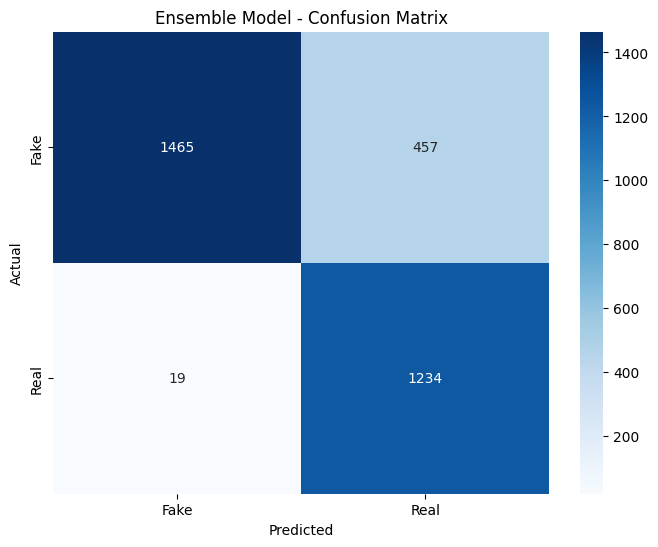

Saved to Drive!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_labels, ensemble_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Real'],
            yticklabels=['Fake', 'Real'])
plt.title('Ensemble Model - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig('/content/drive/MyDrive/confusion_matrix.png')
plt.show()
print("Saved to Drive!")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ১. Dataset overview
print("=== Dataset Overview ===")
print(f"Total rows: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")
print(f"\nColumn names: {df.columns.tolist()}")
print(f"\nSample data:")
print(df[['text', 'subject', 'level']].head(10))

# ২. Label distribution
print("\n=== Label Distribution ===")
print("0 = Fake, 1 = Real")
print(df['label'].value_counts())

# ৩. Language distribution
print("\n=== Language Distribution ===")
print(df['language'].value_counts())

# ৪. Subject distribution
print("\n=== Subject Distribution ===")
print(df['subject'].value_counts())

=== Dataset Overview ===
Total rows: 15874
Total columns: 5

Column names: ['text', 'subject', 'level', 'label', 'clean_text']

Sample data:
                                                text          subject  level
0  new york reuters us environmental group sierra...     politicsNews    0.0
1  washington reuters us air force asked industry...     politicsNews    0.0
2  saturday paul ryan posted photo instagram phot...             News    1.0
3  america keeps waiting word hillary indicted ob...         politics    1.0
4                   religion peace ht weasel zippers        left-news    1.0
5  leave obama politicize money think past presid...  Government News    1.0
6  knew donald trump would nightmare supreme cour...             News    1.0
7  like soldiers oden vigilante group reported fe...  Government News    1.0
8  kiev reuters outgoing us vice president joe bi...     politicsNews    0.0
9  detroit reuters quality problems prompted two ...     politicsNews    0.0

=== Label D

KeyError: 'language'

In [ ]:
from langdetect import detect

def detect_lang(text):
    try:
        return detect(str(text))
    except:
        return 'unknown'

print("Language detection")
df['language'] = df['text'].apply(detect_lang)
print("Done!")
print(df['language'].value_counts())

Language detection
Done!
language
bn    9091
en    6761
fr       6
pl       2
sw       2
sk       1
cy       1
nl       1
pt       1
sq       1
ca       1
it       1
sl       1
tl       1
lt       1
tr       1
de       1
Name: count, dtype: int64


/tmp/ipykernel_1718/3025021290.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['language'] = df['text'].apply(detect_lang)


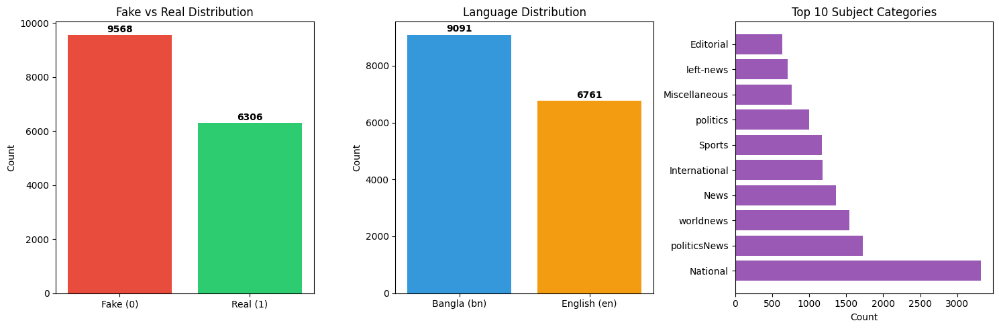

Chart saved to Drive!


In [ ]:
# Language distribution chart
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Chart 1: Fake vs Real
labels = ['Fake (0)', 'Real (1)']
values = [9568, 6306]
axes[0].bar(labels, values, color=['#e74c3c', '#2ecc71'])
axes[0].set_title('Fake vs Real Distribution')
axes[0].set_ylabel('Count')
for i, v in enumerate(values):
    axes[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# Chart 2: Language distribution
lang_labels = ['Bangla (bn)', 'English (en)']
lang_values = [9091, 6761]
axes[1].bar(lang_labels, lang_values, color=['#3498db', '#f39c12'])
axes[1].set_title('Language Distribution')
axes[1].set_ylabel('Count')
for i, v in enumerate(lang_values):
    axes[1].text(i, v + 100, str(v), ha='center', fontweight='bold')

# Chart 3: Top 10 subjects
top_subjects = df['subject'].value_counts().head(10)
axes[2].barh(top_subjects.index, top_subjects.values, color='#9b59b6')
axes[2].set_title('Top 10 Subject Categories')
axes[2].set_xlabel('Count')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/dataset_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved to Drive!")

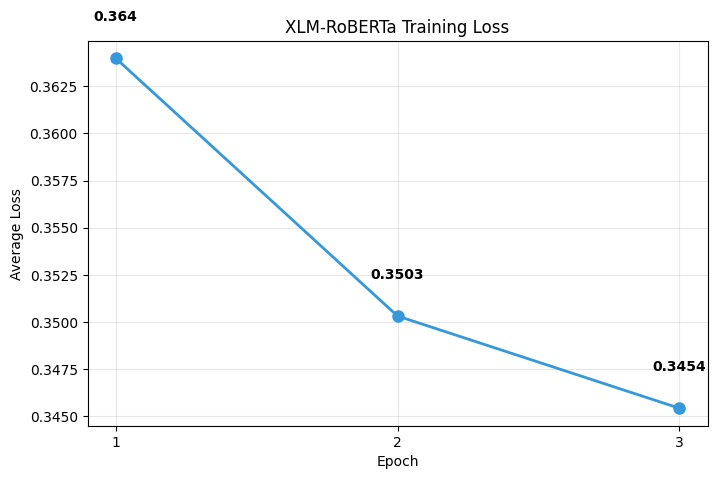

Saved to Drive!


In [ ]:
# Training Loss Graph
epochs = [1, 2, 3]
losses = [0.3640, 0.3503, 0.3454]

plt.figure(figsize=(8, 5))
plt.plot(epochs, losses, marker='o', color='#3498db', linewidth=2, markersize=8)
plt.title('XLM-RoBERTa Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
for i, (e, l) in enumerate(zip(epochs, losses)):
    plt.text(e, l + 0.002, str(l), ha='center', fontweight='bold')
plt.savefig('/content/drive/MyDrive/training_loss.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to Drive!")

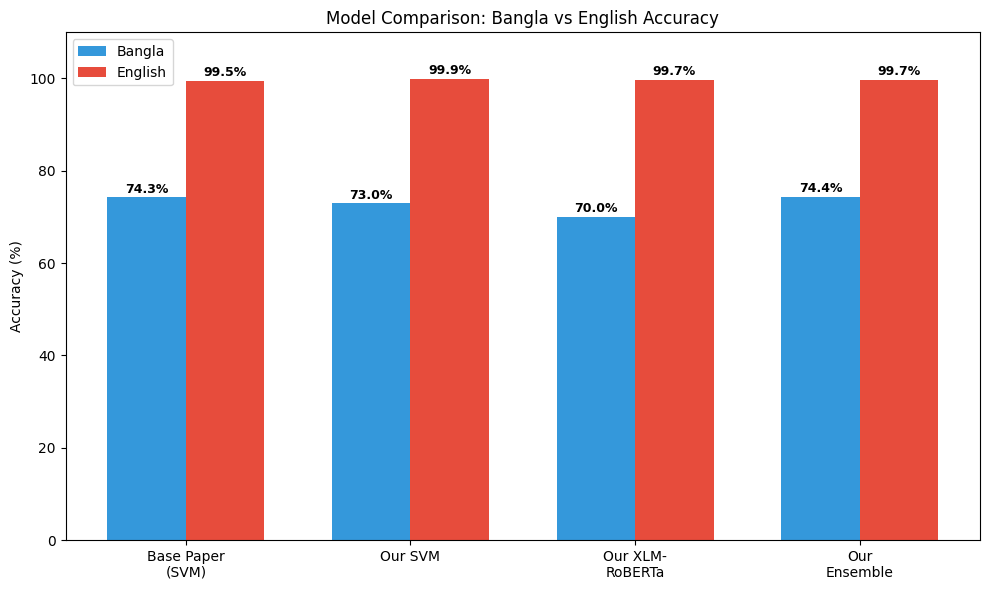

Saved to Drive!


In [ ]:
# Final Model Comparison Chart
models = ['Base Paper\n(SVM)', 'Our SVM', 'Our XLM-\nRoBERTa', 'Our\nEnsemble']
bangla = [74.3, 73.0, 70.0, 74.4]
english = [99.5, 99.9, 99.7, 99.7]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, bangla, width, label='Bangla', color='#3498db')
bars2 = ax.bar(x + width/2, english, width, label='English', color='#e74c3c')

ax.set_title('Model Comparison: Bangla vs English Accuracy')
ax.set_ylabel('Accuracy (%)')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.set_ylim(0, 110)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height()}%', ha='center', fontsize=9, fontweight='bold')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height()}%', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to Drive!")

In [ ]:
export_df = df[['text', 'clean_text', 'subject', 'label', 'language']].copy()


export_df['label_name'] = export_df['label'].map({0: 'Fake', 1: 'Real'})
export_df['language_name'] = export_df['language'].map({'bn': 'Bangla', 'en': 'English'})

export_df.to_excel('/content/drive/MyDrive/processed_dataset.xlsx', index=False)
print("Done! Total rows:", len(export_df))
print(export_df.head())

Done! Total rows: 15874
                                                text  \
0  new york reuters us environmental group sierra...   
1  washington reuters us air force asked industry...   
2  saturday paul ryan posted photo instagram phot...   
3  america keeps waiting word hillary indicted ob...   
4                   religion peace ht weasel zippers   

                                          clean_text       subject  label  \
0  new york reuters us environmental group sierra...  politicsNews      0   
1  washington reuters us air force asked industry...  politicsNews      0   
2  saturday paul ryan posted photo instagram phot...          News      1   
3  america keeps waiting word hillary indicted ob...      politics      1   
4                   religion peace ht weasel zippers     left-news      1   

  language label_name language_name  
0       en       Fake       English  
1       en       Fake       English  
2       en       Real       English  
3       en       Real   

In [ ]:
export_df = export_df[export_df['language'].isin(['bn', 'en'])]

export_df.to_excel('/content/drive/MyDrive/processed_dataset.xlsx', index=False)
print("Done! Total rows:", len(export_df))
print(export_df['language'].value_counts())

Done! Total rows: 15852
language
bn    9091
en    6761
Name: count, dtype: int64


In [ ]:
export_df = df[df['language'].isin(['bn', 'en'])][['text', 'clean_text', 'subject', 'level', 'label', 'language']].copy()


export_df['label_name'] = export_df['label'].map({0: 'Fake', 1: 'Real'})
export_df['language_name'] = export_df['language'].map({'bn': 'Bangla', 'en': 'English'})

export_df.to_excel('/content/drive/MyDrive/processed_dataset.xlsx', index=False)
print("Done! Total rows:", len(export_df))
print("\nLabel distribution:")
print(export_df['label_name'].value_counts())
print("\nLanguage distribution:")
print(export_df['language_name'].value_counts())

Done! Total rows: 15852

Label distribution:
label_name
Fake    9547
Real    6305
Name: count, dtype: int64

Language distribution:
language_name
Bangla     9091
English    6761
Name: count, dtype: int64
